# Dynamic Programming: Planning in FrozenLake

**Family:** Reinforcement learning | **Level:** Beginner | **Dataset:** `FrozenLake-v1` | **Runs on:** CPU, about 1 minute(s)

Solve a known MDP exactly with policy iteration and value iteration.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- The Bellman optimality equation
- Policy evaluation, improvement and iteration
- Why DP needs a model of the environment
- How slippery transitions change the best policy

**Prerequisites:**

- Probability basics
- Markov decision processes

**Skills you will have afterwards:**

- Run several seeds
- Report learning curves with spread
- Compare with a baseline policy

## 2. Real-World Problem

**Context.** A robot crosses a frozen lake where the ice is slippery, so a move sometimes goes sideways.

**The problem.** Find the policy that reaches the goal most often when the transition probabilities are known.

**Why it matters.** Planning with a model is the reference that learning methods are measured against.

**Why machine learning.** The best action depends on uncertain outcomes several steps ahead.

**Why this algorithm.** DP gives exact answers for small known MDPs.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Reinforcement Learning: An Introduction (2nd ed.)

- **Type:** foundational paper
- **Authors:** Sutton, R. S. and Barto, A. G.
- **Year and venue:** 2018, MIT Press
- **DOI or URL:** http://incompleteideas.net/book/the-book-2nd.html
- **Verification:** not verified in build environment
- **Research objective:** Textbook covering dynamic programming, Monte Carlo, TD, policy gradient.
- **Methodology:** Textbook.
- **Dataset:** Not applicable.
- **Main findings:** Reference text for this section.
- **Limitations:** Textbook, not an experiment.

### Gymnasium: A Standard Interface for Reinforcement Learning Environments

- **Type:** benchmark paper
- **Authors:** Towers, M. et al.
- **Year and venue:** 2024, arXiv:2407.17032
- **DOI or URL:** https://arxiv.org/abs/2407.17032
- **Verification:** arXiv abstract page 2026-11-17
- **Research objective:** Describe the Gymnasium API.
- **Methodology:** Software paper.
- **Dataset:** Not applicable.
- **Main findings:** Standard reset and step interface.
- **Limitations:** Software description.

**Relationship to this notebook.** Sutton and Barto (not verified in the build environment, check before citing) present policy and value iteration. Towers et al. describe the Gymnasium API used for the environment. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Bellman expectation.** $V^\pi(s) = \sum_a \pi(a|s)\sum_{s',r} p(s',r|s,a)[r + \gamma V^\pi(s')]$.

**Bellman optimality.** $V^*(s) = \max_a \sum_{s',r} p(s',r|s,a)[r + \gamma V^*(s')]$.

**Value iteration.** Apply the optimality backup until the largest change is below a threshold $\theta$.

**Policy iteration.** Alternate full policy evaluation and greedy improvement. It stops when the policy no longer changes, after a finite number of rounds.

**Limits.** Needs $p(s',r|s,a)$, cost grows with the number of states.

## 5. Dataset Introduction

**FrozenLake-v1** (Gymnasium, `toy_text`), 4 by 4 grid with 16 states and 4 actions. Reward is 1 only on reaching the goal. With `is_slippery=True` the agent moves in the intended direction with probability 1/3 and sideways otherwise. There is no dataset: the environment is simulated. The transition model is read from `env.unwrapped.P`. We also use the 8 by 8 map.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from IPython.display import display

from ml_lab.rl import tabular, deep
from ml_lab.evaluation import evaluate_policy
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "dynamic_programming"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()
print("gymnasium", gym.__version__)

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
gymnasium 1.4.0


## 6. Exploratory Data Analysis

There is no dataset. We inspect the environment: observation and action spaces, rewards and a random policy baseline. 

In [2]:
env = gym.make("FrozenLake-v1", is_slippery=True)
print("observation space:", env.observation_space, "| action space:", env.action_space)
print(env.unwrapped.desc.astype(str))
P, nS, nA = tabular.transition_model("FrozenLake-v1", is_slippery=True)
print("transitions from state 0, action 'right' (probability, next, reward, done):", P[0][2])

observation space: Discrete(16) | action space: Discrete(4)
[['S' 'F' 'F' 'F']
 ['F' 'H' 'F' 'H']
 ['F' 'F' 'F' 'H']
 ['H' 'F' 'F' 'G']]
transitions from state 0, action 'right' (probability, next, reward, done): [(0.33333333333333337, 4, 0, False), (0.3333333333333333, 1, 0, False), (0.33333333333333337, 0, 0, False)]


## 7. Data Preprocessing

The environment is deterministic in its rules but random in its outcomes. We read the transition model once and use the discount factor 0.99 for planning. For the success probability we also evaluate with discount 1, which makes the value of the start state equal to the probability of reaching the goal.

In [3]:
GAMMA = 0.99
P, nS, nA = tabular.transition_model("FrozenLake-v1", is_slippery=True)
print("states:", nS, "| actions:", nA)

states: 16 | actions: 4


## 8. Algorithm Implementation

### 8.1 Concept

Because the model is known, we do not need to interact. We sweep over the states and back up values until they stop changing.

### 8.2 Python implementation from scratch

The implementation is in `ml_lab.rl.tabular`. We print the source of value iteration so that it can be read here.

In [4]:
print(inspect.getsource(tabular.value_iteration))

def value_iteration(P, n_states, n_actions, gamma=0.99, theta=1e-10):
    values = np.zeros(n_states)
    sweeps = 0
    while True:
        delta = 0.0
        for s in range(n_states):
            best = max(sum(p * (r + gamma * values[s2] * (not done)) for p, s2, r, done in P[s][a]) for a in range(n_actions))
            delta = max(delta, abs(best - values[s]))
            values[s] = best
        sweeps += 1
        if delta < theta:
            break
    policy = q_from_values(P, values, n_states, n_actions, gamma).argmax(axis=1)
    return values, policy, sweeps



### 8.3 Library implementation

The algorithm is implemented in `src/ml_lab/rl` without an RL library. Gymnasium supplies only the environment.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `gamma` | Discount factor. |
| `theta` | Stopping threshold for value change. |
| `is_slippery` | Whether moves are random. |

## 9. Model Training

Run value iteration and policy iteration on the 4 by 4 and 8 by 8 maps and compare the policies and the number of sweeps.

In [5]:
results = {}
for size, name in [("4x4", "4x4"), ("8x8", "8x8")]:
    P_, nS_, nA_ = tabular.transition_model("FrozenLake-v1", map_name=size, is_slippery=True)
    V_vi, pol_vi, sweeps = tabular.value_iteration(P_, nS_, nA_, GAMMA)
    V_pi, pol_pi, rounds = tabular.policy_iteration(P_, nS_, nA_, GAMMA)
    results[size] = dict(P=P_, nS=nS_, V=V_vi, policy=pol_vi, sweeps=sweeps, rounds=rounds, same=bool(np.allclose(V_vi, V_pi, atol=1e-6)))
    print(size, "| VI sweeps:", sweeps, "| PI rounds:", rounds, "| same values:", results[size]["same"], "| same policy:", bool(np.array_equal(pol_vi, pol_pi)))

4x4 | VI sweeps: 420 | PI rounds: 7 | same values: True | same policy: True


8x8 | VI sweeps: 440 | PI rounds: 11 | same values: True | same policy: False


## 10. Evaluation

Exact success probability: evaluate the optimal policy with discount 1. Check it by simulating 5000 episodes (the simulation has a binomial standard error of about 0.7 percentage points). The floor is the uniformly random policy, also evaluated exactly.

In [6]:
table = {}
for size, r in results.items():
    n = r["nS"]
    exact, _ = tabular.policy_evaluation(r["P"], r["policy"], n, gamma=1.0)
    uniform = np.zeros(n)
    for _ in range(3000):
        for s in range(n):
            uniform[s] = np.mean([sum(p * (rw + uniform[s2] * (not d)) for p, s2, rw, d in r["P"][s][a]) for a in range(4)])
    env = gym.make("FrozenLake-v1", map_name=size, is_slippery=True)
    wins = 0
    for i in range(5000):
        s, _ = env.reset(seed=1000 + i)
        done = False
        while not done:
            s, rew, term, trunc, _ = env.step(int(r["policy"][s]))
            done = term or trunc
        wins += rew > 0
    table[size] = {"exact_success_optimal": float(exact[0]), "simulated_success_optimal": wins / 5000, "exact_success_random": float(uniform[0]), "VI_sweeps": r["sweeps"], "PI_rounds": r["rounds"]}
display(pd.DataFrame(table).T.round(4))
METRICS = {**{f"{k}_{size}": v for size, d in table.items() for k, v in d.items()}}
CONFIG = {"gamma": GAMMA, "theta": 1e-10, "maps": ["4x4", "8x8"]}
EXTRA = {"optimal_policy_4x4": [int(a) for a in results["4x4"]["policy"]]}

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="reinforcement_learning", algorithm="ValueIteration", dataset="FrozenLake-v1",
                          task="control", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

,exact_success_optimal,simulated_success_optimal,exact_success_random,VI_sweeps,PI_rounds
4x4,0.8235,0.7286,0.0139,420.0,7.0
8x8,0.8938,0.6254,0.0019,440.0,11.0


saved: /home/claude/open-python/experiments/results/dynamic_programming.json


,metric
exact_success_optimal_4x4,0.8235
simulated_success_optimal_4x4,0.7286
exact_success_random_4x4,0.0139
VI_sweeps_4x4,420.0000
PI_rounds_4x4,7.0000
exact_success_optimal_8x8,0.8938
simulated_success_optimal_8x8,0.6254
exact_success_random_8x8,0.0019
VI_sweeps_8x8,440.0000
PI_rounds_8x8,11.0000


## 11. Visualization

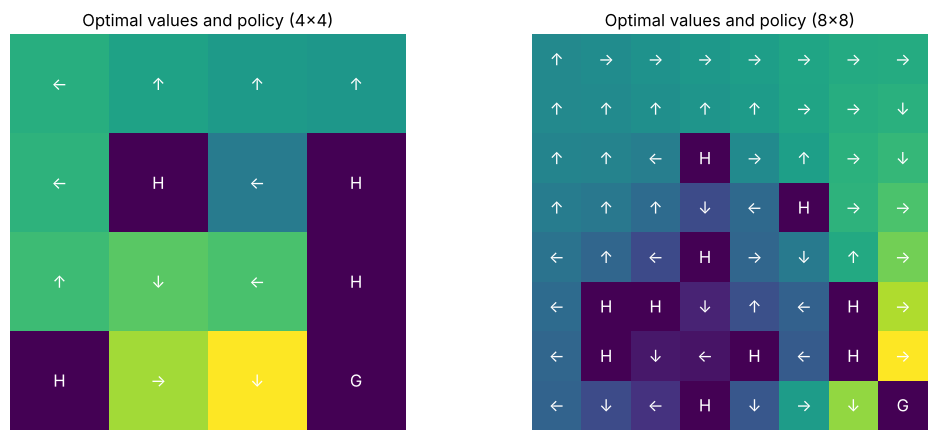

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
arrows = {0: "←", 1: "↓", 2: "→", 3: "↑"}
for ax, size, n in [(axes[0], "4x4", 4), (axes[1], "8x8", 8)]:
    V = results[size]["V"].reshape(n, n)
    ax.imshow(V, cmap="viridis")
    desc = gym.make("FrozenLake-v1", map_name=size).unwrapped.desc.astype(str)
    for i in range(n):
        for j in range(n):
            tile = desc[i, j]
            ax.text(j, i, tile if tile in "HG" else arrows[int(results[size]["policy"][i * n + j])], ha="center", va="center", color="white", fontsize=12)
    ax.set_title(f"Optimal values and policy ({size})"); ax.axis("off")
plt.tight_layout(); save_figure(fig, NOTEBOOK_ID, "policy"); plt.show()

## 12. Interpretation

The policy often moves away from holes even when that is not the direct route, because a slippery move may go sideways.

In [8]:
print("optimal action in each 4x4 state (0 left, 1 down, 2 right, 3 up):")
print(results["4x4"]["policy"].reshape(4, 4))

optimal action in each 4x4 state (0 left, 1 down, 2 right, 3 up):
[[0 3 3 3]
 [0 0 0 0]
 [3 1 0 0]
 [0 2 1 0]]


## 13. Experiments and Challenges

### Experiment 1: Slippery versus deterministic ice

Plan on the deterministic lake and compare the success probability.

In [9]:
P_d, nS_d, nA_d = tabular.transition_model("FrozenLake-v1", is_slippery=False)
_, pol_d, _ = tabular.value_iteration(P_d, nS_d, nA_d, GAMMA)
exact_d, _ = tabular.policy_evaluation(P_d, pol_d, nS_d, gamma=1.0)
print("deterministic lake: success probability of the optimal policy", float(exact_d[0]))

deterministic lake: success probability of the optimal policy 1.0


### Experiment 2: Discount factor

A smaller gamma makes the agent care less about distant reward.

In [10]:
for g in [0.5, 0.9, 0.99, 1.0]:
    V, pol, sw = tabular.value_iteration(results["4x4"]["P"], 16, 4, g)
    exact, _ = tabular.policy_evaluation(results["4x4"]["P"], pol, 16, gamma=1.0)
    print(f"gamma={g}: sweeps {sw}, success probability of the resulting policy {float(exact[0]):.4f}")

gamma=0.5: sweeps 23, success probability of the resulting policy 0.4507
gamma=0.9: sweeps 110, success probability of the resulting policy 0.7805
gamma=0.99: sweeps 420, success probability of the resulting policy 0.8235
gamma=1.0: sweeps 591, success probability of the resulting policy 0.8235


### Experiment 3: Cost of a sweep

Count how the work grows with the number of states.

In [11]:
for size in ["4x4", "8x8"]:
    r = results[size]
    print(size, "states", r["nS"], "| backups until convergence", r["nS"] * r["sweeps"])

4x4 states 16 | backups until convergence 6720
8x8 states 64 | backups until convergence 28160


### Exercises for learners

1. Repeat with a different set of seeds and report the spread.
2. Change the discount factor and describe what happens to the learned behaviour.
3. Change one hyperparameter by a factor of 10 and compare learning curves.

## 14. Research Discussion

The textbook describes DP as exact but limited by model knowledge and state count. Our two map sizes show the second limit directly in the number of backups.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Use asynchronous or prioritised sweeps and compare with sampling based methods.

**Research limitations.** One dataset and one seed for the headline numbers. Few seeds (see the notebook), small environments, and no hyperparameter search beyond the experiments shown.

## 15. Summary and Further Reading

**Key takeaways**

- DP needs the model.
- Value and policy iteration reach the same optimum.
- Slippery ice lowers the best possible success rate.

**Use cases.** Planning in small known MDPs, reference solutions.

**Limitations.** Needs a model, small state spaces.

**Recommended next notebook.** Monte Carlo methods.

**Further reading.** See `references.md` in this folder.